# 07 · Why customers leave: Netflix app reviews (NLP)

**Owner:** Sukhraj · **Phase 8** of the StayScope pipeline

Notebooks 05 and 06 predict **who** churns and which measurable behaviour goes with it (tenure, viewing time, price,
support tickets). None of our datasets records **why** a customer left. Public Google Play reviews of the Netflix
app are customers explaining it in their own words, so this notebook mines them:

1. **Data and cleaning:** 165,694 reviews (Sep 2018 to Nov 2026), Kaggle *Netflix Reviews (Play Store, daily updated)*.
2. **Sentiment:** the star rating is the label. A text classifier checks how much the words alone reveal, and the
   monthly share of negative reviews tracks sentiment over time.
3. **Cancel intent:** reviews that mention cancelling or switching, the closest thing to a stated churn reason.
4. **Topics:** NMF topic model on the negative reviews, grouped into named themes, with a robustness check.
5. **Timeline:** do complaint themes move with real events (price rises, the ad plan, paid sharing)?
6. **Link to the churn models:** which review themes match a churn driver in Dataset S, and which S cannot see.

All logic is in `src/churn/reviews.py`; this notebook only calls it, plots and explains.

**Caveat for the whole notebook:** reviewers choose to write (angry users are over-represented) and cannot be linked to
the customers in S or A. The link to the churn drivers is qualitative support, not proof.

## 1. Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from churn import config, reviews as RV
from churn.plotting import CHURN, MEDIUM, NEUTRAL, RETAINED, savefig, set_style

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
set_style()
config.ensure_dirs()
SENT_COLORS = {"negative": CHURN, "neutral": NEUTRAL, "positive": RETAINED}
LABELS = {k: v["label"] for k, v in RV.THEMES.items()} | {"other": "Other", "cancel_intent": "Mentions cancelling"}


def add_events(ax):
    """Dashed lines for the real-world events in RV.EVENTS, labelled vertically so close dates do not overlap."""
    for when, what in RV.EVENTS:
        x = pd.Period(when, "M").to_timestamp()
        ax.axvline(x, color=NEUTRAL, lw=0.8, ls="--", alpha=0.7)
        ax.text(x, 0.98, what + " ", transform=ax.get_xaxis_transform(), fontsize=7.5, color=NEUTRAL,
                rotation=90, ha="right", va="top")

## 2. Data and cleaning

`RV.run()` loads the raw file (the reviewer name is dropped on load, as it is personal data we do not need), cleans
it, fits the topic model and writes every Phase 8 output to `reports/results/`. The steps are explained below.

In [2]:
out = RV.run()
df, neg, cancel = out["clean"], out["neg"], out["cancel"]
raw_n = out["log"]["rows_before"].iloc[0]
print(f"{raw_n:,} raw reviews -> {len(df):,} after cleaning ({len(df) / raw_n:.1%} kept), "
      f"{df['date'].min():%b %Y} to {df['date'].max():%b %Y}")
out["log"]

165,694 raw reviews -> 145,174 after cleaning (87.6% kept), Sep 2018 to Nov 2026


,dataset,step,rows_before,rows_after,n_affected,note
0,reviews,drop_empty,165694,165686,8,review has no text
1,reviews,drop_duplicate_ids,165686,163879,1807,same review scraped twice
2,reviews,drop_duplicate_text,163879,151797,12082,"identical text, first kept (spam, 'good app' repeats)"
3,reviews,drop_short,151797,146080,5717,"fewer than 3 words, too short for a topic"
4,reviews,drop_non_english,146080,145174,906,5+ words but no English stop word (other languages in Latin script)


* **Duplicates** are the biggest step: 1,807 reviews were scraped twice, and 12,082 are exact copies of an earlier
  text. Most of those are one-liners like "good app" or "nice", plus some copy-pasted spam, and they would only
  inflate the counts.
* **Short reviews** (fewer than 3 words) have no topic to find.
* **Non-English:** the app is reviewed worldwide. Reviews in other scripts carry no English stop words and drop out
  of the topic vocabulary anyway. The extra rule removes long reviews in Latin-script Hindi, Tagalog and similar
  (5+ words and not a single English stop word). It is a cheap filter that needs no language-detection package.

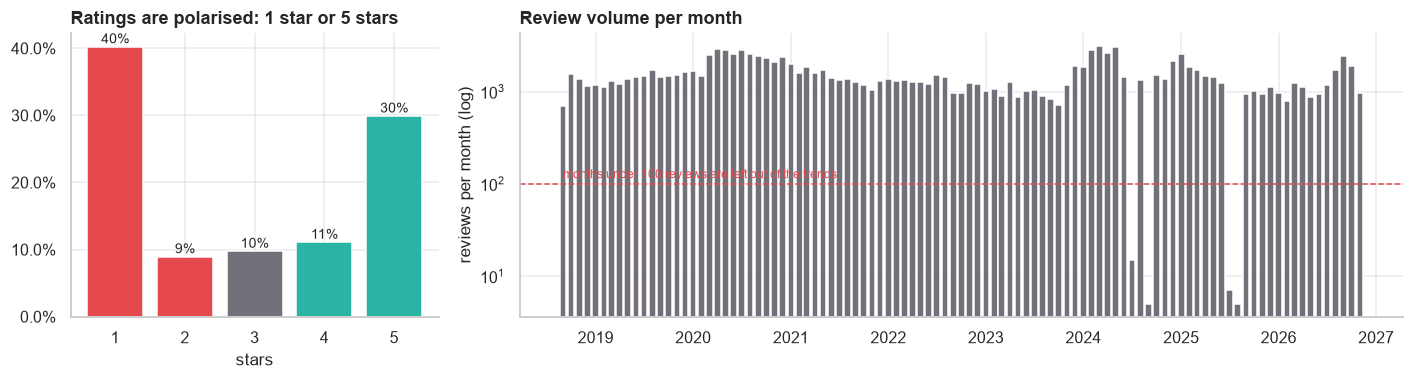

{'negative': 0.492, 'positive': 0.41, 'neutral': 0.098}


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2.4]})
shares = df["score"].value_counts(normalize=True).sort_index()
axes[0].bar(shares.index, shares.values, color=[SENT_COLORS[RV.SENTIMENT_LABELS[s]] for s in shares.index])
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_xlabel("stars")
axes[0].set_title("Ratings are polarised: 1 star or 5 stars")
for s, v in shares.items():
    axes[0].text(s, v + 0.005, f"{v:.0%}", ha="center", fontsize=9)

monthly = df.groupby("month").size()
axes[1].bar(monthly.index, monthly.values, width=25, color=NEUTRAL)
axes[1].axhline(config.REVIEW_MIN_MONTH_N, color=CHURN, lw=1, ls="--")
axes[1].text(monthly.index[0], config.REVIEW_MIN_MONTH_N * 1.15,
             f"months under {config.REVIEW_MIN_MONTH_N} reviews are left out of the trends", color=CHURN, fontsize=8)
axes[1].set_yscale("log")
axes[1].set_ylabel("reviews per month (log)")
axes[1].set_title("Review volume per month")
fig.tight_layout()
savefig(fig, "07_reviews_overview")
plt.show()
print(df["sentiment"].value_counts(normalize=True).round(3).to_dict())

Half the reviews are negative (1–2 stars) and only 10% are neutral. App-store reviews are written mostly by people
who are either very happy or very annoyed, which is why the negative share is far above any real churn rate. The
volume has gaps (a few months with almost no scraped reviews); those months are left out of the monthly series.

## 3. Sentiment

**Label:** the star rating, written by the reviewer: 1–2 stars = negative, 3 = neutral, 4–5 = positive.

*Why not a sentiment lexicon such as VADER?* We already have a label the reviewer chose themselves, which beats any
lexicon's guess. Lexicons also struggle with this kind of text: sarcasm, "not bad", and technical complaints with no
emotional words ("black screen after update"). We use the text differently: a **TF-IDF + Logistic Regression**
classifier shows how much of the rating the words explain, and its coefficients show which words mark a complaint.

Protocol, same as the churn models: 70/15/15 stratified split of the non-neutral reviews, C tuned on validation
(seed 0), each of the 5 seeds evaluated once on its test split.

In [4]:
sent_metrics, coef, best_c = RV.sentiment_model(df)
print(f"C = {best_c} (tuned on validation)")
summary = sent_metrics.drop(columns=["seed", "C"]).agg(["mean", "std"]).T
summary["mean ± std"] = summary["mean"].map("{:.3f}".format) + " ± " + summary["std"].map("{:.3f}".format)
summary[["mean ± std"]]

C = 2 (tuned on validation)


,mean ± std
accuracy,0.901 ± 0.002
precision,0.901 ± 0.002
recall,0.921 ± 0.001
f1,0.911 ± 0.001
roc_auc,0.956 ± 0.001
pr_auc,0.955 ± 0.001


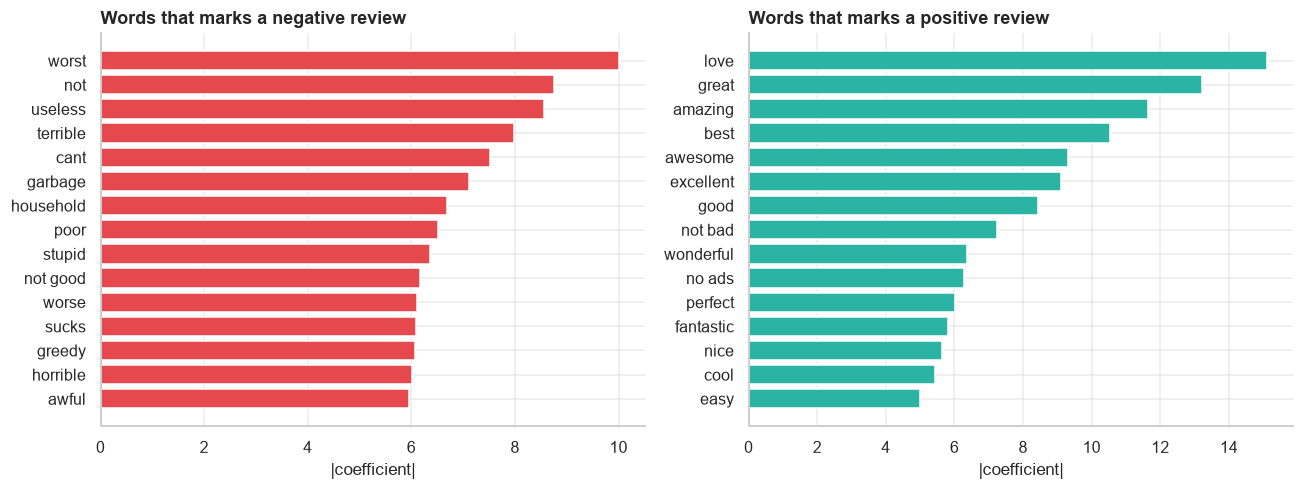

In [5]:
top = pd.concat([coef.head(15).assign(side="marks a negative review"),
                 coef.tail(15).assign(side="marks a positive review")])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (side, d), color in zip(axes, top.groupby("side", sort=False), [CHURN, RETAINED]):
    d = d.reindex(d["coef"].abs().sort_values().index)
    ax.barh(d["term"], d["coef"].abs(), color=color)
    ax.set_title(f"Words that {side}")
    ax.set_xlabel("|coefficient|")
fig.tight_layout()
savefig(fig, "07_sentiment_terms")
plt.show()

The text predicts the rating very well (test ROC-AUC 0.956 ± 0.001), so the review text and the stars tell the same
story and the stars are a sound label. Most of the strongest words are plain emotion ("worst", "useless", "great"),
but several name a **reason**: *household*, *greedy*, *not worth*, *cancelled / canceling* and *Kannada* (missing
regional-language content). "No ads" marks a positive review. These reasons come back in the topic model below.

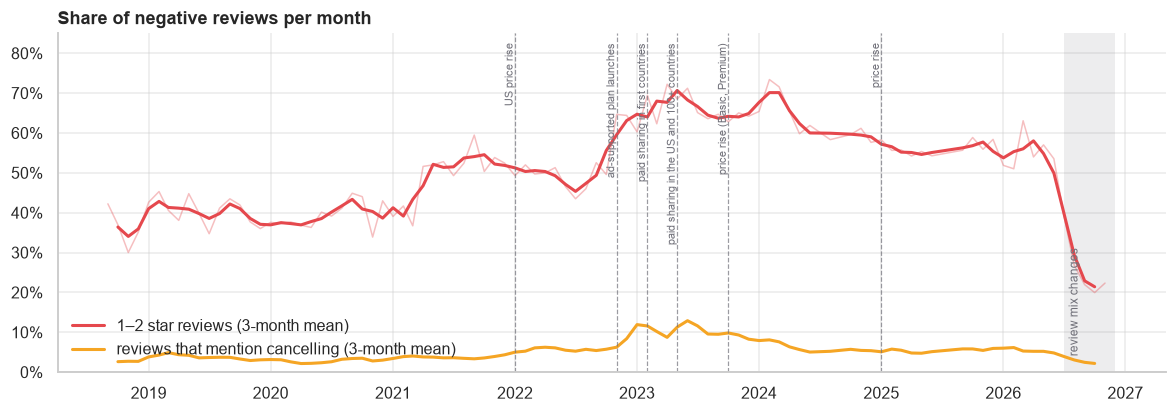

,negative_share,cancel_share
year,,
2018,0.361,0.027
2019,0.405,0.038
2020,0.393,0.028
2021,0.493,0.038
2022,0.516,0.058
2023,0.658,0.104
2024,0.634,0.062
2025,0.562,0.054
2026,0.419,0.043


In [6]:
sent = out["sentiment"]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(sent["month"], sent["negative_share"], color=CHURN, lw=1, alpha=0.35)
ax.plot(sent["month"], sent["negative_share"].rolling(3, center=True).mean(), color=CHURN, lw=2,
        label="1–2 star reviews (3-month mean)")
ax.plot(sent["month"], sent["cancel_share"].rolling(3, center=True).mean(), color=MEDIUM, lw=2,
        label="reviews that mention cancelling (3-month mean)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 0.85)
ax.set_title("Share of negative reviews per month")
ax.axvspan(pd.Timestamp("2026-07-01"), sent["month"].max() + pd.Timedelta(days=31), color=NEUTRAL, alpha=0.12, lw=0)
ax.text(pd.Timestamp("2026-07-15"), 0.04, "review mix changes", fontsize=8, color=NEUTRAL, rotation=90,
        va="bottom")
ax.legend(loc="lower left")
add_events(ax)
savefig(fig, "07_sentiment_over_time")
plt.show()
sent.assign(year=sent["month"].dt.year).groupby("year")[["negative_share", "cancel_share"]].mean()

Negative reviews rose from about 36–40% (2018–2020) to a peak of **66% in 2023**, and mentions of cancelling more
than doubled the same year (4% → 10%). 2023 is when paid sharing rolled out and the second large price rise
landed. Through 2024 to mid-2026 the negative share eased to about 55%.

**The drop after mid-2026 (grey band) is a change in who writes reviews, not a recovery.** From August 2026 the monthly
volume doubles (about 1,300 → 2,700–3,700), the median review gets shorter (14 → 10 words), and almost all of the extra
reviews are positive. That pattern fits a change in how reviews are requested, for example an in-app rating prompt,
rather than suddenly happier customers. Treat those months as a different population. The theme results below are
shares *within* negative reviews, so the shift barely affects them.

More generally, app-store sentiment also moves with buggy releases and with how Google Play prompts for reviews,
so the overall level is only partly comparable across years. Section 6 asks the more specific question: *what* were people complaining about at each point?

## 4. Cancel intent

A review has cancel intent when it mentions cancelling, unsubscribing, switching to another service, a refund or
"not worth it" (`RV.CANCEL_PATTERN`). It is a keyword rule, so it catches "I will cancel if…" as well as "I cancelled",
but either way the writer is naming a reason they would leave.

In [7]:
print(f"{len(cancel):,} reviews with cancel intent ({len(cancel) / len(df):.1%} of all), "
      f"{cancel['negative'].mean():.0%} of them 1–2 stars")
display(cancel.nlargest(6, "thumbs_up")[["score", "thumbs_up", "date", "content"]])

7,051 reviews with cancel intent (4.9% of all), 87% of them 1–2 stars


,score,thumbs_up,date,content
50529,2,3045,2020-11-21 02:38:17,"When I first joined Netflix, it was like $8 per month. The price is steady increasing but the movie quality is not. ..."
42726,1,2342,2022-05-28 10:57:40,Interface is a mess. It's so hard to scan tv shows and movies. You keep scrolling right then if there's something in...
38613,1,2281,2024-03-11 15:58:21,Netflix keep getting worse and worse. Literally unusable for travel and offline downloads. Travelling a lot for work...
42707,1,2087,2023-02-19 22:30:41,I've had Netflix since 2011. Used to be the cream of the crop for streaming sites. But it is getting impossible to j...
39007,5,2018,2024-02-19 08:49:43,I've been a member of Netflix for a good few years now and have never had a problem I watch Netflix on my Amazon fir...
42719,1,1854,2022-06-09 11:50:57,"Price increase should mean a better experience. However, I'm have an issue connecting to Netflix on my android Tab. ..."


## 5. Topics: what are the negative reviews about?

### Why NMF?
We need a method that finds complaint themes nobody labelled, that we can explain in a report, and that runs on
72K reviews on a laptop. **NMF** (non-negative matrix factorisation) on TF-IDF fits all three:

* **Readable by construction:** it writes each review as a *non-negative* mix of topics, and each topic as a
  non-negative list of words. Nothing cancels out, so a topic's top words *are* the topic.
* **Good on short text:** LDA, the classic alternative, assumes each document is a long mix of many topics and needs
  lots of words per document to estimate it. Reviews are 20 words on average and usually have one complaint, and
  NMF on TF-IDF handles that better in practice.
* **Light:** scikit-learn only, a fit takes seconds, and results are reproducible with a seed. BERTopic (sentence
  embeddings + clustering) can give better topics, but it adds PyTorch and a transformer model to the project, runs
  far slower, and its clusters are harder to explain in a classwork report.

**Set-up:** TF-IDF of words and word pairs on the negative reviews only, with generic sentiment words removed
("worst", "bad", "great"…). Otherwise NMF builds a topic out of pure anger that says nothing about the *reason*.

### How many topics?
Two checks per k. **Coherence** (NPMI): do a topic's top words actually appear together in reviews?
**Stability**: refit with other seeds and measure how similar the topics are (1 = identical).

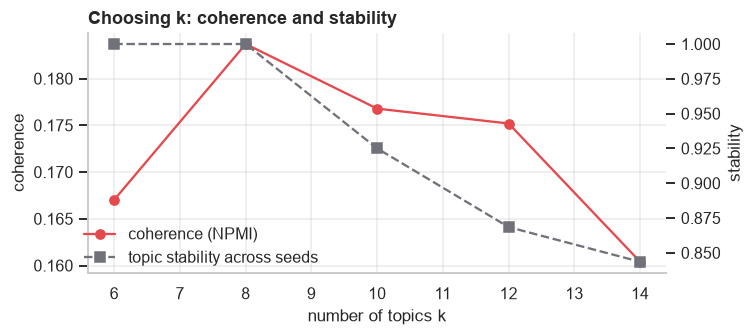

,k,coherence,stability
0,6,0.167,1.000
1,8,0.184,1.000
2,10,0.177,0.925
3,12,0.175,0.868
4,14,0.160,0.844


In [8]:
k_scores = RV.choose_k(neg["text"])
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(k_scores["k"], k_scores["coherence"], "o-", color=CHURN, label="coherence (NPMI)")
ax2 = ax.twinx()
ax2.plot(k_scores["k"], k_scores["stability"], "s--", color=NEUTRAL, label="topic stability across seeds")
ax.set_xlabel("number of topics k")
ax.set_ylabel("coherence")
ax2.set_ylabel("stability")
ax2.grid(False)
ax.set_title("Choosing k: coherence and stability")
fig.legend(loc="lower left", bbox_to_anchor=(0.1, 0.18), frameon=False)
fig.tight_layout()
savefig(fig, "07_choose_k")
plt.show()
k_scores

Coherence is nearly flat between k = 8 and 14 (0.16–0.18). Topic stability drops above k = 8 because NMF splits one
complaint ("the app is broken") into near-synonyms like *stopped working*, *won't open* and *doesn't work*, and the split
differs per seed. That matters less than it seems: each topic is mapped to a **theme** with a keyword lexicon
(`RV.THEMES`), and the near-synonyms all land in the same theme. So we check stability where the results live, at
**theme level**, for k = 8, 10, 12 over 5 seeds:

In [9]:
stab = RV.theme_stability(neg, cancel)
stab_summary = (stab.groupby(["group", "k", "theme"])["share"].agg(["mean", "std"])
                .unstack(["group", "k"]).sort_values(("mean", "negative", 12), ascending=False))
stab_summary

mean                                     std              \
group           cancel             negative             cancel               
k                   8     10    12       8     10    12     8     10    12   
theme                                                                        
price_billing    0.544 0.498 0.498    0.288 0.258 0.235  0.005 0.039 0.024   
app_broken       0.091 0.097 0.106    0.226 0.228 0.226  0.028 0.024 0.019   
playback         0.037 0.103 0.087    0.121 0.177 0.161  0.014 0.017 0.018   
content          0.229 0.204 0.186    0.185 0.140 0.130  0.005 0.052 0.036   
server_error     0.051 0.037 0.042    0.088 0.071 0.074  0.003 0.014 0.016   
bad_update       0.046 0.044 0.043    0.077 0.074 0.072  0.002 0.002 0.002   
account_sharing  0.000 0.004 0.020    0.000 0.010 0.051  0.000 0.008 0.003   
downloads        0.000 0.012 0.016    0.000 0.027 0.036  0.000 0.011 0.009   
other            0.001 0.001 0.001    0.015 0.015 0.015  0.000 0.000 0.000   
ads              0.000 0.000 0.000    0.000 0.000 0.000  0.000 0.000 0.000   

                                      
group           negative              
k                     8     10    12  
theme                                 
price_billing      0.003 0.017 0.009  
app_broken         0.041 0.038 0.028  
playback           0.032 0.030 0.033  
content            0.002 0.034 0.023  
server_error       0.002 0.017 0.019  
bad_update         0.002 0.002 0.001  
account_sharing    0.000 0.023 0.008  
downloads          0.000 0.024 0.020  
other              0.000 0.000 0.000  
ads                0.000 0.000 0.000

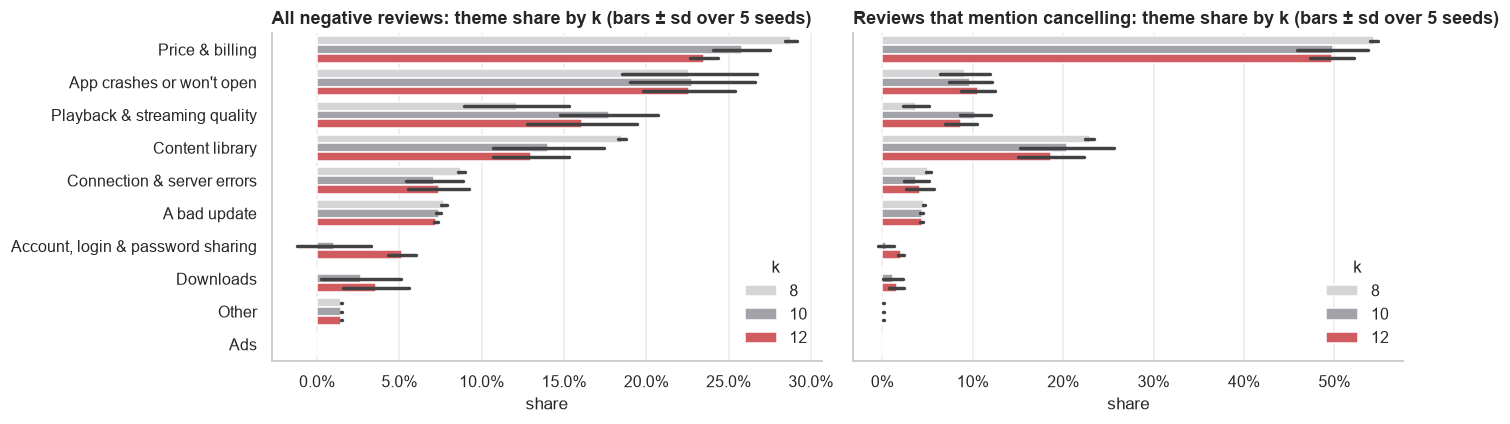

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
order = stab_summary.index.tolist()
for ax, group, title in zip(axes, ["negative", "cancel"], ["All negative reviews", "Reviews that mention cancelling"]):
    d = stab[stab["group"] == group]
    sns.barplot(d, y="theme", x="share", hue="k", order=order, palette=["#D4D4D8", "#A1A1AA", CHURN],
                errorbar="sd", ax=ax)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_yticklabels([LABELS[t] for t in order])
    ax.set_ylabel("")
    ax.set_title(f"{title}: theme share by k (bars ± sd over 5 seeds)")
fig.tight_layout()
savefig(fig, "07_theme_stability")
plt.show()

The theme shares move only a few points with the seed (sd mostly ≤ 0.03, at most 0.06) and tell the same story for every k: price leads the cancel
reviews at about half, content comes second, and broken-app complaints are common overall but rare among people who
say they will leave. We use **k = 12** (`config.REVIEW_N_TOPICS`), the finest setting where the themes are still
stable. It is also the only one that gives login and password problems a topic of their own.

### The 12 topics and their themes

In [11]:
out["topics"].assign(theme=out["topics"]["theme"].map(LABELS))

,nmf_topic,share,top_terms,theme
0,2,0.225,"account, money, pay, subscription, payment, free, month, card, waste, cancel",Price & billing
1,7,0.128,"phone, download, uninstall, tv, restart, android, device, brightness, works, restart phone",App crashes or won't open
2,8,0.095,"shows, tv, shows movies, tv shows, watching, content, movies shows, watch shows, price, better",Content library
3,9,0.079,"watch, movie, watch movie, able watch, watch movies, able, series, watch phone, let, watching",Playback & streaming quality
4,1,0.079,"movies, series, movies series, available, watch movies, kannada, old, download, shows movies, language",Content library
5,5,0.073,"update, new, new update, latest, latest update, recent, recent update, version, old, update open",A bad update
6,6,0.068,"error, service, reach, reach service, sorry, sorry reach, later, getting, service later, says",Connection & server errors
7,0,0.065,"screen, video, black, play, black screen, audio, playing, loading, problem, sound",Playback & streaming quality
8,10,0.057,"sign, keeps, password, crashing, email, log, keeps crashing, account, login, let","Account, login & password sharing"
9,3,0.046,"open, unable open, unable, able open, open phone, crashing, everytime open, everytime, able, crashes",App crashes or won't open


The mapping is automatic: each topic goes to the theme whose keywords match most of its top-20 words, weighted. Read
down the list to check it. Every mapping is sensible. Topic 2 mixes account and payment words, but it is about paying
(money, subscription, card, waste, cancel), so *Price & billing* fits. Two themes have no topic of their own:
**Downloads** and **Ads** are too small for NMF to separate, so they are measured with keywords only (section 6).

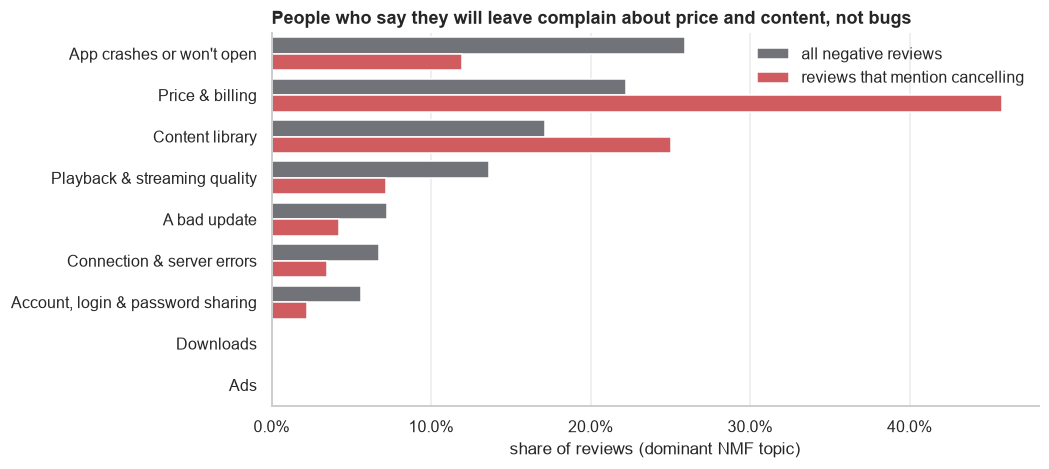

,theme,topic,share,cancel_share,keyword_share,n_reviews,nmf_topics,s_driver
0,app_broken,App crashes or won't open,0.259,0.119,0.421,18521,7 3 4 11,support_tickets_per_month
1,price_billing,Price & billing,0.222,0.458,0.323,15869,2,monthly_charges
2,content,Content library,0.171,0.251,0.342,12247,8 1,viewing_hours_per_week
3,playback,Playback & streaming quality,0.136,0.072,0.403,9728,9 0,support_tickets_per_month
4,bad_update,A bad update,0.073,0.042,0.144,5189,5,support_tickets_per_month
5,server_error,Connection & server errors,0.067,0.035,0.136,4795,6,support_tickets_per_month
6,account_sharing,"Account, login & password sharing",0.056,0.022,0.187,4014,10,multi_device_access
7,downloads,Downloads,0.000,0.000,0.092,0,,content_downloads_per_month
8,ads,Ads,0.000,0.000,0.029,0,,


In [12]:
themes = out["themes"]
d = themes.melt(id_vars="topic", value_vars=["share", "cancel_share"], var_name="group", value_name="value")
d["group"] = d["group"].map({"share": "all negative reviews", "cancel_share": "reviews that mention cancelling"})
fig, ax = plt.subplots(figsize=(9, 4.4))
sns.barplot(d, y="topic", x="value", hue="group", palette=[NEUTRAL, CHURN], ax=ax)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("share of reviews (dominant NMF topic)")
ax.set_ylabel("")
ax.set_title("People who say they will leave complain about price and content, not bugs")
ax.legend(title="")
savefig(fig, "07_theme_shares")
plt.show()
themes.drop(columns=["description"])

**The main result of this notebook.** Two groups of complaints behave very differently:

* **Friction: the app crashes, won't play, errors, bad updates.** These make up about 54% of negative reviews but only
  about 27% of cancel reviews. People are annoyed and leave one star, but a bug is rarely the reason they say they will
  cancel.
* **Value: price and content.** These make up about 39% of negative reviews but **about 71% of cancel reviews**
  (price 46%, content 25%). When people say why they will leave, they say it costs too much for what is in the
  library.

**Keyword check.** `keyword_share` is the share of negative reviews that mention each theme's keywords at all
(multi-label, so it does not sum to 1). The order differs from the NMF shares because short words like *phone*,
*watch* and *account* appear in many reviews, but it confirms the themes are real and gives a size to the two themes
NMF cannot separate: downloads (9% of negative reviews) and ads (3%).

## 6. Timeline: do complaints follow real events?

Quarterly share of negative reviews that mention each theme (keyword flags, so ads and password sharing are visible),
against the main pricing and policy changes (`RV.EVENTS`). The dates are approximate global rollout dates, and the
reviews are global.

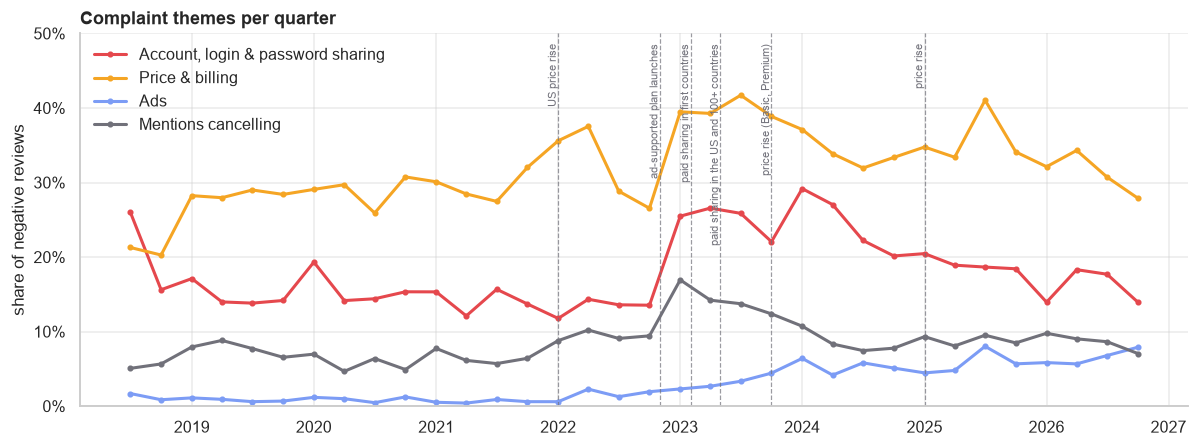

theme,account_sharing,price_billing,ads,cancel_intent
quarter,,,,
2021Q3,0.157,0.275,0.009,0.057
2021Q4,0.137,0.320,0.006,0.064
2022Q1,0.118,0.356,0.006,0.088
2022Q2,0.143,0.375,0.023,0.102
2022Q3,0.136,0.288,0.013,0.091
2022Q4,0.135,0.265,0.019,0.094
2023Q1,0.255,0.395,0.023,0.169
2023Q2,0.266,0.393,0.027,0.142
2023Q3,0.259,0.417,0.033,0.137


In [13]:
trends = out["trends"].assign(date=lambda d: pd.PeriodIndex(d["quarter"], freq="Q").to_timestamp(how="start"))
show = {"account_sharing": CHURN, "price_billing": MEDIUM, "ads": "#7C9CF5", "cancel_intent": NEUTRAL}
fig, ax = plt.subplots(figsize=(13, 4.4))
for theme, color in show.items():
    d = trends[trends["theme"] == theme]
    ax.plot(d["date"], d["share"], "o-", ms=3, lw=2, color=color, label=LABELS[theme])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 0.5)
ax.set_ylabel("share of negative reviews")
ax.set_title("Complaint themes per quarter")
ax.legend(loc="upper left")
add_events(ax)
savefig(fig, "07_theme_trends")
plt.show()
trends.pivot(index="quarter", columns="theme", values="share")[list(show)].loc["2021Q3":"2024Q2"]

The themes line up with the events:

* **Account & password sharing** stays flat at about 12–15% of negative reviews until 2022, then jumps to **26% in
  2023 Q1** when paid sharing started, and peaks at 29% in 2024 Q1. Mentions of cancelling jump at the same time
  (9% → 17%). It is the clearest event in the data.
* **Price** complaints rise with each price increase: 32% → 36–38% in early 2022, and about 39–42% through 2023.
* **Ads** were almost never mentioned before late 2022 (under 1%). After the ad plan launched they climb to 4–8%, and
  keep rising as the plan grows.
* After 2024 the sharing complaints fade (14–18%). People either paid, left or stopped writing about it, but price
  complaints stay high.

The timeline is correlational: reviews that mention a theme rise *when* the policy arrives, which is strong evidence
the policy is what people are reacting to. It does not tell us how many of them actually cancelled.

## 7. Link to the churn models

Each theme has the Dataset S feature that measures the same thing (`RV.THEMES[...]["s_driver"]`), next to that
feature's share of SHAP importance in the S model (notebook 06).

In [14]:
fi = pd.read_csv(config.RESULTS_DIR / "feature_importance.csv")
shap_s = fi[(fi["experiment"] == "S_full") & (fi["method"] == "shap")].set_index("feature")["importance"]
link = themes[["topic", "share", "cancel_share", "keyword_share", "s_driver"]].copy()
link["s_shap_importance"] = link["s_driver"].map(shap_s)
link["s_driver"] = link["s_driver"].replace("", "none in S")
link

,topic,share,cancel_share,keyword_share,s_driver,s_shap_importance
0,App crashes or won't open,0.259,0.119,0.421,support_tickets_per_month,0.086
1,Price & billing,0.222,0.458,0.323,monthly_charges,0.105
2,Content library,0.171,0.251,0.342,viewing_hours_per_week,0.135
3,Playback & streaming quality,0.136,0.072,0.403,support_tickets_per_month,0.086
4,A bad update,0.073,0.042,0.144,support_tickets_per_month,0.086
5,Connection & server errors,0.067,0.035,0.136,support_tickets_per_month,0.086
6,"Account, login & password sharing",0.056,0.022,0.187,multi_device_access,0.000
7,Downloads,0.000,0.000,0.092,content_downloads_per_month,0.138
8,Ads,0.000,0.000,0.029,none in S,NaN


**Where reviews and models agree:**
* **Price** is the top stated reason for leaving (46% of cancel reviews), and `monthly_charges` is a clear churn driver
  in S (10.5% of SHAP importance; churn rises from about 12% to 25% across the price range).
* **Content and engagement:** content is the second stated reason (25%). In S, low viewing hours, short sessions and
  few downloads (`viewing_hours_per_week`, `avg_viewing_duration`, `content_downloads_per_month`) together carry
  about 44% of the importance. Customers who do not find enough to watch watch less and leave, and reviewers say the
  same thing in words.
* **Friction:** bugs and errors are the biggest complaint group, and in S `support_tickets_per_month` raises churn
  (8.6% importance), though it is a weaker driver than price or engagement. That matches the reviews, where friction
  makes people angry but is rarely the stated reason to cancel.

**What only the reviews can see:**
* **Password sharing and ads** are among the strongest events in the reviews, but S has no feature for them. Its
  `multi_device_access` flag carries 0.0% importance, and S has no ad-supported plan at all. A real churn model
  for Netflix after 2023 would need these (plan type with or without ads, extra-member status).
* The reverse is true for **tenure** (`account_age`, the top S driver at 22%). Reviews never say how long someone
  has been a customer, so they cannot confirm or deny it.

## 8. Example reviews per theme

The most-upvoted reviews that clearly belong to each theme (`reviews_examples.csv`, used by the app's drill-down).

In [15]:
ex = out["examples"]
for theme, g in ex.groupby("topic", sort=False):
    print(f"\n=== {theme}")
    for _, r in g.head(2).iterrows():
        print(f"  [{r['score']}★, {r['thumbs_up']:,} upvotes] {r['content'][:260]}")


=== Account, login & password sharing
  [1★, 51 upvotes] So all of a sudden, out of nowhere, I can't sign into the app. I have no problem signing in on my web browser. Even did so and changed my password but, even with the new password, still can't sign into the app. Care to explain Netflix? I've been a customer sin
  [1★, 50 upvotes] The only home feature ruined netflix, now when I try to sign in from any device, it says I need to watch it either temporary or to sign out. Now I can't even watch it. Terrible experience.

=== App crashes or won't open
  [1★, 920 upvotes] App Does Not Work!!!! I keep getting a (-74) error when I tried to log in earlier. I tried uninstalling and reinstalling the app multiple times. I restarted my phone. Now the app crashes, it does not even open!! There is no issue with my internet and my Netfli
  [1★, 482 upvotes] I'm giving it one star for now. I've been loving Netflix until a few days ago that it stopped working. I can't control it using my Google TV 

## 9. Outputs and conclusions

Written by `RV.run()` to `reports/results/`:

| File | Content |
|---|---|
| `reviews_topics.csv` | one row per theme: topic (label), share, cancel_share, keyword_share, n_reviews, nmf_topics, s_driver |
| `reviews_sentiment.csv` | month, n_reviews, negative_share, mean_score, cancel_share |
| `reviews_theme_trends.csv` | quarter, theme, share, n_negative (keyword flags) |
| `reviews_examples.csv` | theme, topic, score, thumbs_up, date, content |
| `reviews_cleaning_log.csv` | cleaning steps (same format as `cleaning_log.csv`) |

**Conclusions**
1. Half of all app reviews are negative, and the share peaked in 2023 (66%), when paid sharing launched. Text alone predicts the star rating with
   ROC-AUC 0.956, so the stars are a reliable sentiment label.
2. Negative reviews are mostly about **friction** (crashes, playback, errors, updates: about 54%), but people who say they
   will **cancel** mostly cite **value**: price (46%) and content (25%).
3. Complaints follow real events. Password-sharing complaints doubled when paid sharing launched (2023 Q1),
   price complaints rose with each price increase, and ads went from almost never mentioned to 4–8% after the ad plan.
4. The reviews support the S churn drivers for price and engagement, and support friction as a weaker one. They also
   point to two reasons S cannot capture: **password-sharing rules and ads**.

**Limitations:** reviewers are self-selected and global, and cannot be linked to S/A customers. Cancel intent is a
keyword rule, not a confirmed cancellation. Theme labels come from a hand-written lexicon (checked above).